# Customer Churn Prediction using Machine Learning

**Internship Final Project – AI/ML | Zynvex Solutions (Batch 5)**

**Problem statement:** A telecom company loses revenue when customers leave (churn).
Acquiring a new customer costs far more than keeping an existing one. This project builds a
machine learning model that predicts **whether a customer will churn (Yes/No)** so the company can
reach out to high-risk customers early.

**Dataset:** Telco Customer Churn (7,043 customers, 21 columns).

**Steps:** Load data → Clean → EDA → Preprocess → Train models → Evaluate → Save best model → Predict

## 1. Import Libraries

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
os.makedirs("images", exist_ok=True)
os.makedirs("models", exist_ok=True)

## 2. Load the Dataset
The notebook downloads the CSV from a public GitHub link. If you are running locally and the file
`data/Telco-Customer-Churn.csv` exists, it is used instead.

In [2]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
LOCAL = "data/Telco-Customer-Churn.csv"

df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand the Data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
print("Duplicate rows:", df.duplicated().sum())
print()
print("Churn counts:")
print(df["Churn"].value_counts())
print()
print("Churn %:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Duplicate rows: 0

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn %:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


## 4. Data Cleaning
`TotalCharges` is stored as text because some rows contain a blank space.
These belong to new customers (tenure = 0), so we convert the column to numbers and fill the gaps with 0.
`customerID` is only an identifier, so it is dropped.

In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges before:", df["TotalCharges"].isnull().sum())

df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing TotalCharges after :", df["TotalCharges"].isnull().sum())

df = df.drop("customerID", axis=1)
print("Total missing values:", df.isnull().sum().sum())

Missing TotalCharges before: 11
Missing TotalCharges after : 0
Total missing values: 0


## 5. Exploratory Data Analysis (EDA)

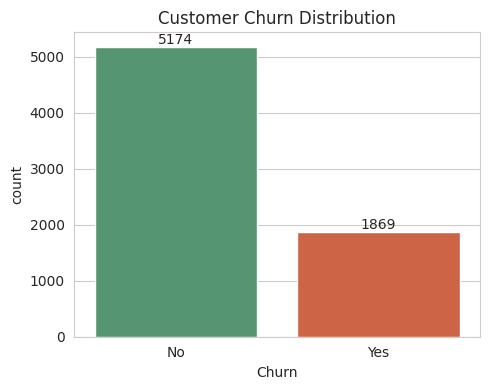

In [9]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Churn", data=df, palette=["#4C9F70", "#E4572E"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Customer Churn Distribution")
plt.tight_layout()
plt.savefig("images/churn_distribution.png", dpi=150)
plt.show()

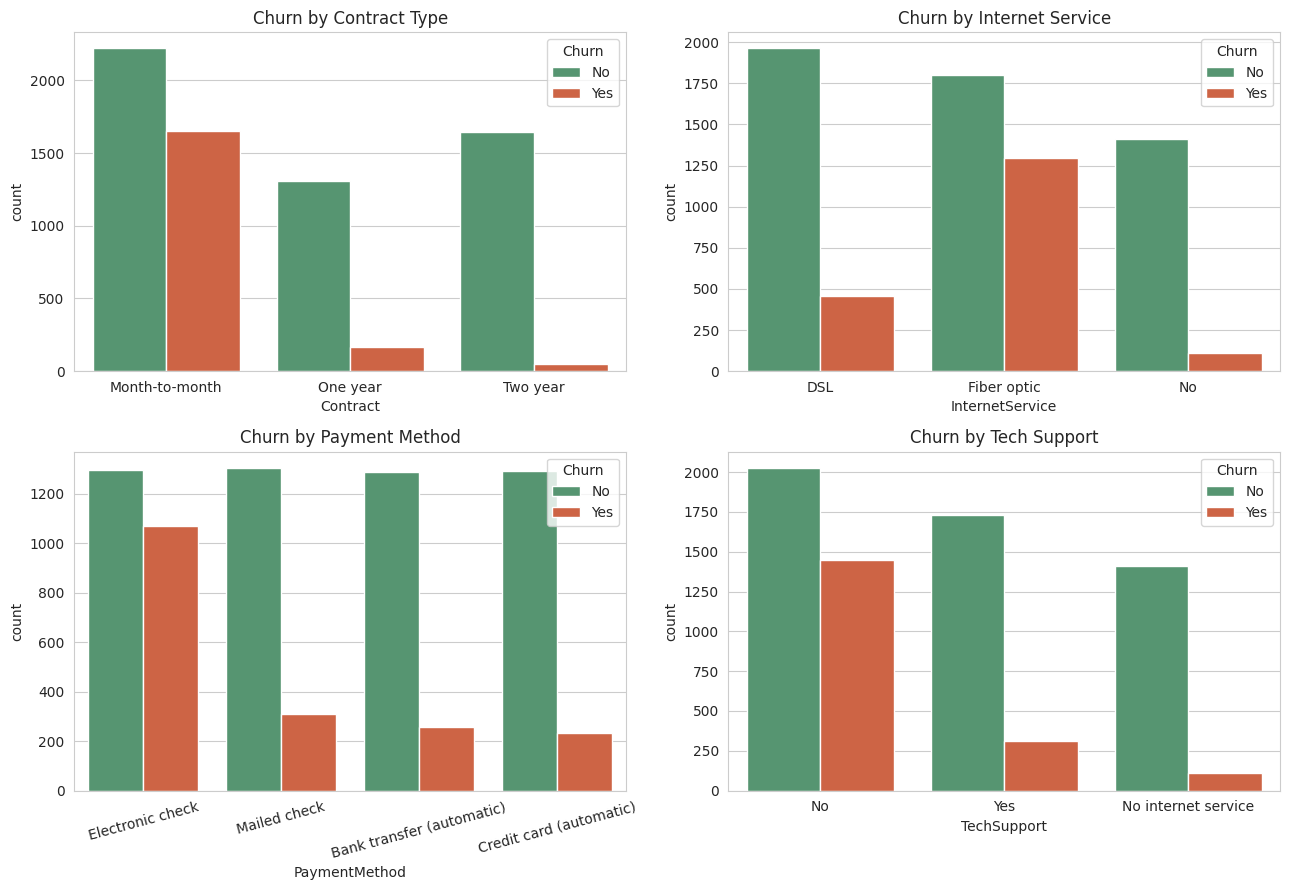

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(x="Contract", hue="Churn", data=df, ax=axes[0, 0], palette=["#4C9F70", "#E4572E"])
axes[0, 0].set_title("Churn by Contract Type")

sns.countplot(x="InternetService", hue="Churn", data=df, ax=axes[0, 1], palette=["#4C9F70", "#E4572E"])
axes[0, 1].set_title("Churn by Internet Service")

sns.countplot(x="PaymentMethod", hue="Churn", data=df, ax=axes[1, 0], palette=["#4C9F70", "#E4572E"])
axes[1, 0].set_title("Churn by Payment Method")
axes[1, 0].tick_params(axis="x", rotation=15)

sns.countplot(x="TechSupport", hue="Churn", data=df, ax=axes[1, 1], palette=["#4C9F70", "#E4572E"])
axes[1, 1].set_title("Churn by Tech Support")

plt.tight_layout()
plt.savefig("images/churn_by_categories.png", dpi=150)
plt.show()

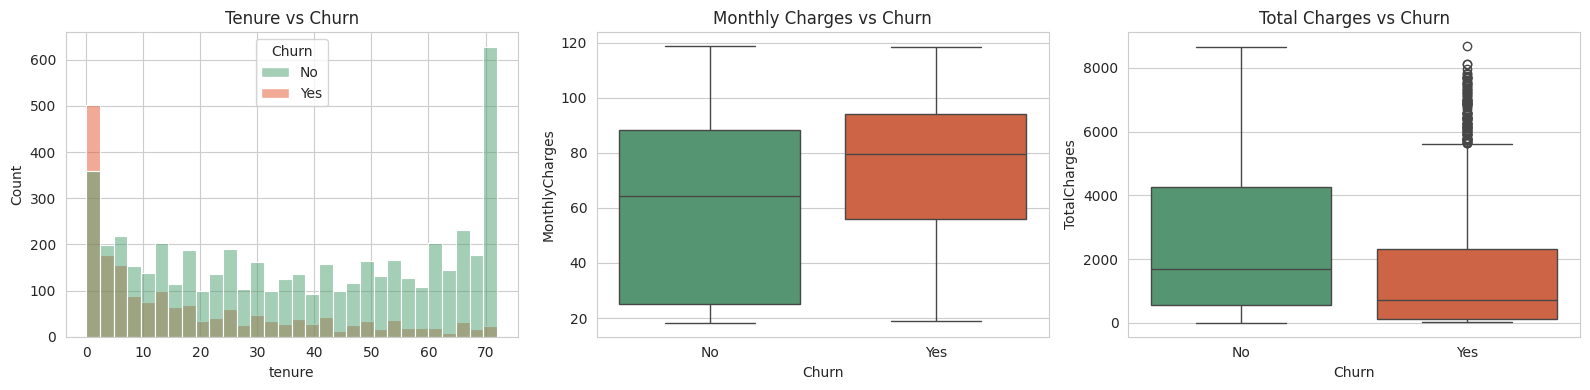

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[0], palette=["#4C9F70", "#E4572E"])
axes[0].set_title("Tenure vs Churn")

sns.boxplot(x="Churn", y="MonthlyCharges", data=df, ax=axes[1], palette=["#4C9F70", "#E4572E"])
axes[1].set_title("Monthly Charges vs Churn")

sns.boxplot(x="Churn", y="TotalCharges", data=df, ax=axes[2], palette=["#4C9F70", "#E4572E"])
axes[2].set_title("Total Charges vs Churn")

plt.tight_layout()
plt.savefig("images/numeric_vs_churn.png", dpi=150)
plt.show()

**Observations**
- About 26.5% of customers churned, so the data is **imbalanced**.
- Customers on **month-to-month contracts** churn far more than those on 1-2 year contracts.
- **Fiber optic** customers and customers **without tech support** churn more.
- Customers who churn usually have a **low tenure** (they leave early) and **higher monthly charges**.

## 6. Data Preprocessing
1. Convert the target `Churn` into numbers (Yes = 1, No = 0).
2. Convert text columns to numbers with **one-hot encoding** (`pd.get_dummies`).
3. Split into **training (80%)** and **testing (20%)** sets (stratified so both keep the same churn ratio).
4. Scale the features with **StandardScaler** (needed for Logistic Regression and KNN).

In [12]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

X = df.drop("Churn", axis=1)
y = df["Churn"]

X = pd.get_dummies(X, drop_first=True)
print("Features after encoding:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train size:", X_train.shape, " Test size:", X_test.shape)

Features after encoding: 30
Train size: (5634, 30)  Test size: (1409, 30)


In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 7. Build and Compare Models
We train four classification models and compare them. Because only ~26% of customers churn,
accuracy alone is misleading, so we also look at **precision, recall and F1-score** for the churn class.

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42),
}

results = []
trained = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    trained[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.807,0.658,0.567,0.609
KNN,0.759,0.550,0.516,0.532
Decision Tree,0.794,0.631,0.540,0.582
Random Forest,0.803,0.675,0.500,0.575


### Handling class imbalance
The models above miss many churners (low recall). Using `class_weight="balanced"` makes the model
pay more attention to the minority class (customers who churn).

In [15]:
balanced_models = {
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree (balanced)": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=200, max_depth=8,
                                                       class_weight="balanced", random_state=42),
}

for name, model in balanced_models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    trained[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df.sort_values("F1-score", ascending=False)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Random Forest (balanced),0.764,0.538,0.783,0.638
Decision Tree (balanced),0.735,0.500,0.807,0.618
Logistic Regression (balanced),0.740,0.507,0.786,0.616
Logistic Regression,0.807,0.658,0.567,0.609
Decision Tree,0.794,0.631,0.540,0.582
Random Forest,0.803,0.675,0.500,0.575
KNN,0.759,0.550,0.516,0.532


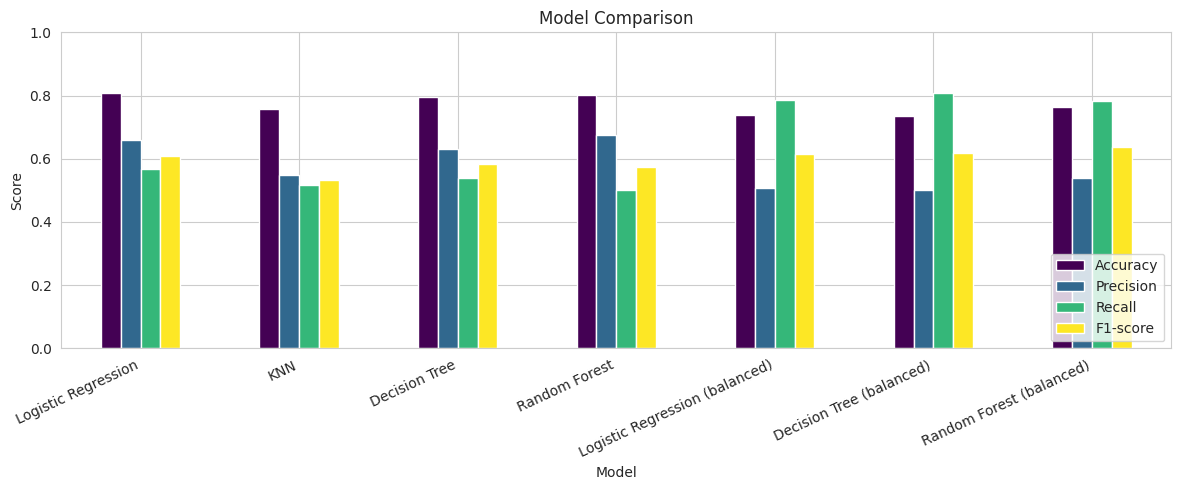

In [16]:
results_df[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(12, 5), colormap="viridis")
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=150)
plt.show()

## 8. Select and Evaluate the Best Model
For churn, **catching customers who will leave (recall)** matters, but we also do not want too many false alarms.
The **F1-score** balances both, so we choose the model with the highest F1-score.

In [17]:
best_name = results_df["F1-score"].idxmax()
best_model = trained[best_name]
print("Best model:", best_name)

y_pred = best_model.predict(X_test_scaled)

print()
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

Best model: Random Forest (balanced)

              precision    recall  f1-score   support

      Stayed       0.91      0.76      0.82      1035
     Churned       0.54      0.78      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.78      1409



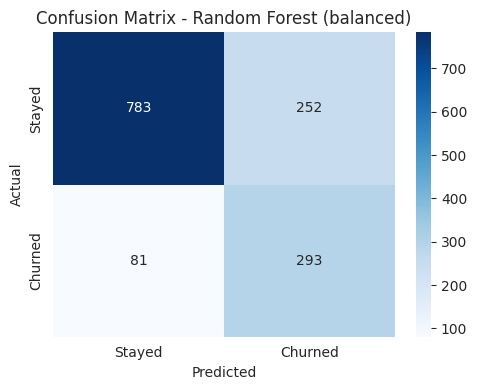

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=150)
plt.show()

## 9. Feature Importance (What drives churn?)

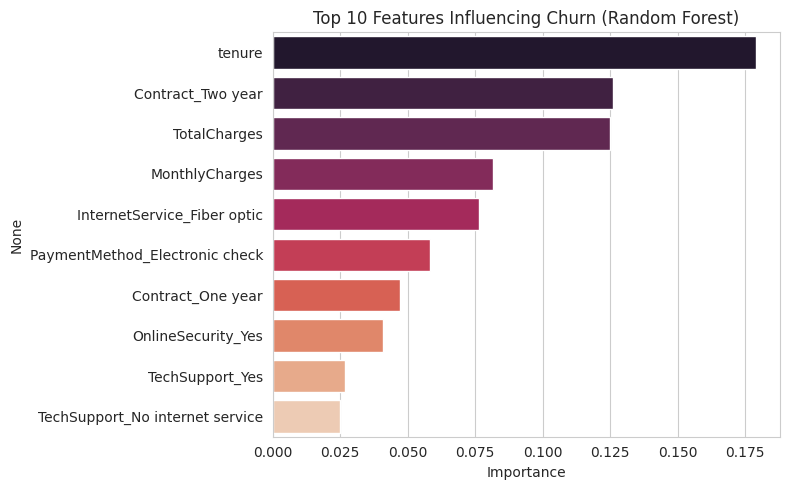

,0
tenure,0.178995
Contract_Two year,0.125895
TotalCharges,0.124836
MonthlyCharges,0.081757
InternetService_Fiber optic,0.076429
PaymentMethod_Electronic check,0.058401
Contract_One year,0.047016
OnlineSecurity_Yes,0.040804
TechSupport_Yes,0.026667
TechSupport_No internet service,0.025029


In [19]:
rf = trained["Random Forest (balanced)"]

importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, palette="rocket")
plt.title("Top 10 Features Influencing Churn (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150)
plt.show()

importance

## 10. Save the Model

In [20]:
joblib.dump(best_model, "models/churn_model.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(list(X.columns), "models/columns.pkl")
print("Saved: churn_model.pkl, scaler.pkl, columns.pkl")

Saved: churn_model.pkl, scaler.pkl, columns.pkl


## 11. Predict for a New Customer

In [21]:
# A new customer (same columns as the original dataset, without customerID and Churn)
new_customer = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No",
    "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 80.0, "TotalCharges": 160.0,
}

model = joblib.load("models/churn_model.pkl")
scaler_loaded = joblib.load("models/scaler.pkl")
columns = joblib.load("models/columns.pkl")

row = pd.get_dummies(pd.DataFrame([new_customer]))
row = row.reindex(columns=columns, fill_value=0)

prob = model.predict_proba(scaler_loaded.transform(row))[0][1]
print(f"Churn probability: {prob:.2%}")
print("Prediction:", "WILL CHURN" if prob >= 0.5 else "WILL STAY")

Churn probability: 86.18%
Prediction: WILL CHURN


## 12. Results, Conclusion and Future Approach

**Results**
- The best model is **Random Forest with balanced class weights** (F1 = 0.63, churn recall = 0.80, accuracy = 75%).
- Without balancing, models reach ~80% accuracy but catch only ~50-57% of churners; balancing raises recall to ~80% at the cost of some accuracy and precision.
- Main churn drivers (feature importance): **tenure, total charges, contract type, monthly charges, fiber-optic internet and electronic-check payment**.

**Business recommendations**
- Offer discounts or upgrades to encourage **month-to-month** customers to move to longer contracts.
- Give extra support to **new customers** (first few months) since churn is highest there.
- Promote **tech support / online security** add-ons to reduce churn.

**Future approach**
- Try advanced models (XGBoost, Gradient Boosting) and hyper-parameter tuning (GridSearchCV).
- Use SMOTE for better handling of imbalance.
- Deploy the model as a live web app and connect it to real customer data.